# TED Talks Dataset — Data Cleaning Notebook
### Data Science Project | Pandas · Data Quality · Outlier Inspection

**Objective:** inspect, clean, validate, and save the TED Talks dataset while preserving valid observations.

This notebook documents the data-cleaning workflow performed on a dataset containing approximately **4,005 rows and 19 columns**.

### Cleaning principles
- Inspect the data before changing it.
- Preserve the original file and work on a DataFrame in memory.
- Fix formatting safely without rewriting titles or names unnecessarily.
- Do not automatically delete statistical outliers.
- Keep values that cannot be verified (such as a missing recording date) unresolved rather than guessing.
- Save the cleaned dataset as a new CSV file.

## 1. Import the required libraries

**What this cell does:** imports Pandas for data handling, NumPy for numerical operations, Matplotlib for plots, and Python utilities for checking URLs and file paths.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
from urllib.parse import urlparse

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)

## 2. Load the dataset

**What this cell does:** reads the original CSV into a DataFrame called `df`.

**Before running:** update `file_path` if your CSV has a different name or is stored in another folder. Keep the original CSV unchanged.

In [2]:
file_path = r"C:\Users\ADITI CHAUDHARY\Downloads\archive\2020-05-01\ted_talks_en.csv"  # Change this to your original CSV path if needed

df = pd.read_csv(file_path)

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded successfully.
Dataset shape: (4005, 19)


,talk_id,title,speaker_1,all_speakers,occupations,about_speakers,views,recorded_date,published_date,event,native_lang,available_lang,comments,duration,topics,related_talks,url,description,transcript
0,1,Averting the climate crisis,Al Gore,{0: 'Al Gore'},{0: ['climate advocate']},{0: 'Nobel Laureate Al Gore focused the world’s attention on the global climate crisis. Now he’s...,3523392,2006-02-25,2006-06-27,TED2006,en,"['ar', 'bg', 'cs', 'de', 'el', 'en', 'es', 'fa', 'fr', 'fr-ca', 'gl', 'gu', 'he', 'hi', 'hr', 'h...",272.0,977,"['alternative energy', 'cars', 'climate change', 'culture', 'environment', 'global issues', 'sci...","{243: 'New thinking on the climate crisis', 547: 'The business logic of sustainability', 2093: '...",https://www.ted.com/talks/al_gore_averting_the_climate_crisis/,"With the same humor and humanity he exuded in ""An Inconvenient Truth,"" Al Gore spells out 15 way...","Thank you so much, Chris. And it's truly a great honor to have the opportunity to come to this s..."
1,92,The best stats you've ever seen,Hans Rosling,{0: 'Hans Rosling'},{0: ['global health expert; data visionary']},"{0: 'In Hans Rosling’s hands, data sings. Global trends in health and economics come to vivid li...",14501685,2006-02-22,2006-06-27,TED2006,en,"['ar', 'az', 'bg', 'bn', 'bs', 'cs', 'da', 'de', 'el', 'en', 'es', 'et', 'fa', 'fi', 'fr', 'he',...",628.0,1190,"['Africa', 'Asia', 'Google', 'demo', 'economics', 'global issues', 'health', 'statistics', 'glob...","{2056: ""Own your body's data"", 2296: 'A visual history of human knowledge', 620: 'Let my dataset...",https://www.ted.com/talks/hans_rosling_the_best_stats_you_ve_ever_seen/,"You've never seen data presented like this. With the drama and urgency of a sportscaster, statis...","About 10 years ago, I took on the task to teach global development to Swedish undergraduate stud..."
2,7,Simplicity sells,David Pogue,{0: 'David Pogue'},{0: ['technology columnist']},{0: 'David Pogue is the personal technology columnist for the <em>New York Times</em> and a tech...,1920832,2006-02-24,2006-06-27,TED2006,en,"['ar', 'bg', 'de', 'el', 'en', 'es', 'fa', 'fr', 'he', 'hr', 'hu', 'it', 'ja', 'ko', 'nb', 'nl',...",124.0,1286,"['computers', 'entertainment', 'interface design', 'media', 'music', 'performance', 'simplicity'...","{1725: '10 top time-saving tech tips', 2274: 'The first secret of design is ... noticing', 172: ...",https://www.ted.com/talks/david_pogue_simplicity_sells/,"New York Times columnist David Pogue takes aim at technology’s worst interface-design offenders,...","(Music: ""The Sound of Silence,"" Simon & Garfunkel) Hello voice mail, my old friend. (Laughter) I..."
3,53,Greening the ghetto,Majora Carter,{0: 'Majora Carter'},{0: ['activist for environmental justice']},"{0: 'Majora Carter redefined the field of environmental equality, starting in the South Bronx at...",2664069,2006-02-26,2006-06-27,TED2006,en,"['ar', 'bg', 'bn', 'ca', 'cs', 'de', 'en', 'es', 'fa', 'fi', 'fr', 'he', 'hi', 'hr', 'hu', 'it',...",219.0,1116,"['MacArthur grant', 'activism', 'business', 'cities', 'environment', 'green', 'inequality', 'pol...","{1041: '3 stories of local eco-entrepreneurship', 1892: 'A new vision for rebuilding Detroit', 2...",https://www.ted.com/talks/majora_carter_greening_the_ghetto/,"In an emotionally charged talk, MacArthur-winning activist Majora Carter details her fight for e...",If you're here today — and I'm very happy that you are — you've all heard about how sustainable ...
4,66,Do schools kill creativity?,Sir Ken Robinson,{0: 'Sir Ken Robinson'},"{0: ['author', 'educator']}","{0: ""Creativity expert Sir Ken Robinson challenges the way we're educating our children. He cham...",65051954,2006-02-25,2006-06-27,TED2006,en,"['af', 'ar', 'az', 'be', 'bg', 'bn', 'ca', 'cs', 'da', 'de', 'el', 'en', 'eo', 'es', 'et', 'eu',...",4931.0,1164,"['children', 'creativity', 'culture', 'dance', 'education', 'parenting', 'teaching']","{865: 'Bring on the learning revolution!', 1738: ""How to e

## 3. Understand the dataset structure

**What this cell does:** checks the number of rows and columns, column names, data types, and non-null counts. This provides a baseline before cleaning.

In [3]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nFirst five rows:")
display(df.head())

Dataset shape: (4005, 19)

Column names:
['talk_id', 'title', 'speaker_1', 'all_speakers', 'occupations', 'about_speakers', 'views', 'recorded_date', 'published_date', 'event', 'native_lang', 'available_lang', 'comments', 'duration', 'topics', 'related_talks', 'url', 'description', 'transcript']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4005 entries, 0 to 4004
Data columns (total 19 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   talk_id         4005 non-null   int64  
 1   title           4005 non-null   object 
 2   speaker_1       4005 non-null   object 
 3   all_speakers    4001 non-null   object 
 4   occupations     3483 non-null   object 
 5   about_speakers  3502 non-null   object 
 6   views           4005 non-null   int64  
 7   recorded_date   4004 non-null   object 
 8   published_date  4005 non-null   object 
 9   event           4005 non-null   object 
 10  native_lang     4005 non-null

,talk_id,title,speaker_1,all_speakers,occupations,about_speakers,views,recorded_date,published_date,event,native_lang,available_lang,comments,duration,topics,related_talks,url,description,transcript
0,1,Averting the climate crisis,Al Gore,{0: 'Al Gore'},{0: ['climate advocate']},{0: 'Nobel Laureate Al Gore focused the world’s attention on the global climate crisis. Now he’s...,3523392,2006-02-25,2006-06-27,TED2006,en,"['ar', 'bg', 'cs', 'de', 'el', 'en', 'es', 'fa', 'fr', 'fr-ca', 'gl', 'gu', 'he', 'hi', 'hr', 'h...",272.0,977,"['alternative energy', 'cars', 'climate change', 'culture', 'environment', 'global issues', 'sci...","{243: 'New thinking on the climate crisis', 547: 'The business logic of sustainability', 2093: '...",https://www.ted.com/talks/al_gore_averting_the_climate_crisis/,"With the same humor and humanity he exuded in ""An Inconvenient Truth,"" Al Gore spells out 15 way...","Thank you so much, Chris. And it's truly a great honor to have the opportunity to come to this s..."
1,92,The best stats you've ever seen,Hans Rosling,{0: 'Hans Rosling'},{0: ['global health expert; data visionary']},"{0: 'In Hans Rosling’s hands, data sings. Global trends in health and economics come to vivid li...",14501685,2006-02-22,2006-06-27,TED2006,en,"['ar', 'az', 'bg', 'bn', 'bs', 'cs', 'da', 'de', 'el', 'en', 'es', 'et', 'fa', 'fi', 'fr', 'he',...",628.0,1190,"['Africa', 'Asia', 'Google', 'demo', 'economics', 'global issues', 'health', 'statistics', 'glob...","{2056: ""Own your body's data"", 2296: 'A visual history of human knowledge', 620: 'Let my dataset...",https://www.ted.com/talks/hans_rosling_the_best_stats_you_ve_ever_seen/,"You've never seen data presented like this. With the drama and urgency of a sportscaster, statis...","About 10 years ago, I took on the task to teach global development to Swedish undergraduate stud..."
2,7,Simplicity sells,David Pogue,{0: 'David Pogue'},{0: ['technology columnist']},{0: 'David Pogue is the personal technology columnist for the <em>New York Times</em> and a tech...,1920832,2006-02-24,2006-06-27,TED2006,en,"['ar', 'bg', 'de', 'el', 'en', 'es', 'fa', 'fr', 'he', 'hr', 'hu', 'it', 'ja', 'ko', 'nb', 'nl',...",124.0,1286,"['computers', 'entertainment', 'interface design', 'media', 'music', 'performance', 'simplicity'...","{1725: '10 top time-saving tech tips', 2274: 'The first secret of design is ... noticing', 172: ...",https://www.ted.com/talks/david_pogue_simplicity_sells/,"New York Times columnist David Pogue takes aim at technology’s worst interface-design offenders,...","(Music: ""The Sound of Silence,"" Simon & Garfunkel) Hello voice mail, my old friend. (Laughter) I..."
3,53,Greening the ghetto,Majora Carter,{0: 'Majora Carter'},{0: ['activist for environmental justice']},"{0: 'Majora Carter redefined the field of environmental equality, starting in the South Bronx at...",2664069,2006-02-26,2006-06-27,TED2006,en,"['ar', 'bg', 'bn', 'ca', 'cs', 'de', 'en', 'es', 'fa', 'fi', 'fr', 'he', 'hi', 'hr', 'hu', 'it',...",219.0,1116,"['MacArthur grant', 'activism', 'business', 'cities', 'environment', 'green', 'inequality', 'pol...","{1041: '3 stories of local eco-entrepreneurship', 1892: 'A new vision for rebuilding Detroit', 2...",https://www.ted.com/talks/majora_carter_greening_the_ghetto/,"In an emotionally charged talk, MacArthur-winning activist Majora Carter details her fight for e...",If you're here today — and I'm very happy that you are — you've all heard about how sustainable ...
4,66,Do schools kill creativity?,Sir Ken Robinson,{0: 'Sir Ken Robinson'},"{0: ['author', 'educator']}","{0: ""Creativity expert Sir Ken Robinson challenges the way we're educating our children. He cham...",65051954,2006-02-25,2006-06-27,TED2006,en,"['af', 'ar', 'az', 'be', 'bg', 'bn', 'ca', 'cs', 'da', 'de', 'el', 'en', 'eo', 'es', 'et', 'eu',...",4931.0,1164,"['children', 'creativity', 'culture', 'dance', 'education', 'parenting', 'teaching']","{865: 'Bring on the learning revolution!', 1738: ""How to e

## 4. Check for missing values

**What this cell does:** counts missing values and calculates their percentage in each column. Run this before imputing values so the original missingness is documented.

In [4]:
missing_summary = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing Percentage": (df.isna().mean() * 100).round(2)
})

display(missing_summary.sort_values("Missing Count", ascending=False))

,Missing Count,Missing Percentage
comments,655,16.35
occupations,522,13.03
about_speakers,503,12.56
all_speakers,4,0.10
recorded_date,1,0.02
talk_id,0,0.00
title,0,0.00
speaker_1,0,0.00
views,0,0.00
event,0,0.00


### 4.1 Inspect the rows with missing values

**What this cell does:** displays records containing at least one missing value so the missing data can be understood before making decisions.

In [5]:
rows_with_missing = df[df.isna().any(axis=1)]
print("Rows containing at least one missing value:", len(rows_with_missing))
display(rows_with_missing.head(20))

Rows containing at least one missing value: 667


,talk_id,title,speaker_1,all_speakers,occupations,about_speakers,views,recorded_date,published_date,event,native_lang,available_lang,comments,duration,topics,related_talks,url,description,transcript
961,1215,Can we make things that make themselves?,Skylar Tibbits,{0: 'Skylar Tibbits'},{0: ['inventor']},NaN,1075122,2011-02-24,2011-09-01,TED2011,en,"['ar', 'bg', 'cs', 'de', 'el', 'en', 'es', 'eu', 'fa', 'fr', 'he', 'hr', 'hu', 'hy', 'id', 'it',...",165.0,364,"['TED Fellows', 'design', 'technology']","{90: 'Unleash your creativity in a Fab Lab', 183: 'Playing with DNA that self-assembles', 165: '...",https://www.ted.com/talks/skylar_tibbits_can_we_make_things_that_make_themselves/,MIT researcher Skylar Tibbits works on self-assembly -- the idea that instead of building someth...,Today I'd like to show you the future of the way we make things. I believe that soon our buildin...
989,1244,The day I turned down Tim Berners-Lee,Ian Ritchie,{0: 'Ian Ritchie'},{0: ['software entrepreneur']},NaN,645869,2011-07-11,2011-10-12,TEDGlobal 2011,en,"['ar', 'bg', 'cs', 'da', 'de', 'el', 'en', 'es', 'fa', 'fr', 'he', 'hr', 'hu', 'id', 'it', 'ja',...",59.0,341,"['business', 'history', 'technology', 'web']","{484: 'The next web', 319: 'The next 5,000 days of the web', 640: 'The Web as random acts of kin...",https://www.ted.com/talks/ian_ritchie_the_day_i_turned_down_tim_berners_lee/,"Imagine it's late 1990, and you've just met a nice young man named Tim Berners-Lee, who starts t...","Well we all know the World Wide Web has absolutely transformed publishing, broadcasting, commerc..."
1062,1323,"""Women of Hope""",Morley,{0: ' Morley'},{0: ['singer-songwriter']},"{0: 'Recording artist, singer, and composer Morley weaves jazz, soul and folk traditions into a ...",365088,2011-12-01,2012-01-13,TEDxWomen 2011,en,"['ar', 'bg', 'ca', 'cs', 'de', 'el', 'en', 'es', 'fa', 'fr', 'fr-ca', 'he', 'hr', 'hu', 'hy', 'i...",NaN,330,"['TEDx', 'activism', 'music', 'poetry', 'women', 'live music', 'performance']","{823: 'Singing old poems to life', 1068: 'Poems of war, peace, women, power', 870: 'Songs of sec...",https://www.ted.com/talks/morley_women_of_hope/,"Inspired by Aung San Suu Kyi's call to action, ""If you're feeling helpless, help someone,"" Morle...",(Music) ♫ They stood together ♫ ♫ under a tree in tall grass ♫ ♫ on TV ♫ ♫ telling the world ♫ ♫...
1142,1407,I am a pirate,Rick Falkvinge,{0: 'Rick Falkvinge'},NaN,"{0: 'Rick Falkvinge, didn’t plan on becoming a politician, but his dedication to civil liberties...",220557,2013-10-31,2012-04-01,TEDxOslo,en,"['ar', 'el', 'en', 'es', 'fr', 'it', 'ko', 'nl', 'pt', 'pt-br', 'ro', 'ru', 'tr', 'uk', 'zh-cn',...",128.0,1097,"['Internet', 'TEDx', 'global issues', 'politics', 'technology']","{1329: 'Why SOPA is a bad idea', 871: 'Re-examining the remix', 1245: 'Open science now!', 2283:...",https://www.ted.com/talks/rick_falkvinge_i_am_a_pirate/,"The Pirate Party fights for transparency, anonymity and sensible copyright laws. At TEDxOslo, Ri...",Thank y'all! This is going to be a motivational speech. Because — imagine my motivation standing...
1170,1436,Tracking our online trackers,Gary Kovacs,{0: 'Gary Kovacs'},NaN,"{0: 'Gary Kovacs is a technologist and the former CEO of the Mozilla Corporation, where he direc...",2226169,2012-02-29,2012-05-03,TED2012,en,"['ar', 'bg', 'cs', 'de', 'el', 'en', 'es', 'fa', 'fr', 'fr-ca', 'he', 'hr', 'hu', 'id', 'it', 'j...",260.0,399,"['Internet', 'advertising', 'business', 'privacy', 'technology']","{1370: 'All your devices can be hacked', 788: 'The year open data went worldwide', 1328: 'Three ...",https://www.ted.com/talks/gary_kovacs_tracking_our_online_trackers/,"As you surf the Web, information is being collected about you. Web tracking is not 100% evil -- ...","I don't know why, but I'm continually amazed to think that two and a half billion of us around t..."
1241,1515,Image recognition that triggers augmented reality,Matt Mills,"{0: 'Matt Mills', 1: 'Tamara Roukaerts'}",NaN,"{0: 

## 5. Check missing values in important columns

**What this cell does:** reviews missing values in `all_speakers`, `occupations`, `about_speakers`, `comments`, and the date columns. In the initial inspection, these included missing speaker/occupation details, comments, and one recording date.

In [6]:
columns_to_review = [
    col for col in [
        "all_speakers", "occupations", "about_speakers",
        "comments", "recorded_date", "published_date"
    ] if col in df.columns
]

print(df[columns_to_review].isna().sum())

all_speakers        4
occupations       522
about_speakers    503
comments          655
recorded_date       1
published_date      0
dtype: int64


## 6. Handle missing speaker and descriptive information

**What this cell does:** replaces missing or whitespace-only values in selected descriptive columns with `"Unknown"`. This avoids inventing names or biographies.

**Note:** `"Unknown"` is a label for missing information, not a recovered original value.

In [7]:
# Fill missing values in all_speakers
if "all_speakers" in df.columns:
    df["all_speakers"] = (
        df["all_speakers"]
        .replace(r"^\s*$", pd.NA, regex=True)
        .fillna("Unknown")
    )

# Fill missing values in occupations
if "occupations" in df.columns:
    df["occupations"] = (
        df["occupations"]
        .replace(r"^\s*$", pd.NA, regex=True)
        .fillna("Unknown")
    )

# Fill missing values in about_speakers
if "about_speakers" in df.columns:
    df["about_speakers"] = (
        df["about_speakers"]
        .replace(r"^\s*$", pd.NA, regex=True)
        .fillna("Unknown")
    )

print("Missing values after descriptive-column cleaning:")
display(df[columns_to_review].isna().sum())

Missing values after descriptive-column cleaning:


all_speakers        0
occupations         0
about_speakers      0
comments          655
recorded_date       1
published_date      0
dtype: int64

## 7. Convert date columns to datetime

**What this cell does:** converts `recorded_date` and `published_date` into Pandas datetime types. With `errors="coerce"`, unparseable values become `NaT` and can be inspected.

**Important:** one `recorded_date` was missing. It is intentionally left as `NaT` because its correct value has not been verified. Do not enter a placeholder such as `"YYYY-MM-DD"`.

In [17]:
for col in ["recorded_date", "published_date"]:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col], errors="coerce")

print("Date column data types:")
for col in ["recorded_date", "published_date"]:
    if col in df.columns:
        print(f"{col}: {df[col].dtype}")
        print(f"Missing/invalid dates: {df[col].isna().sum()}")

# Display any rows with missing recording dates
if "recorded_date" in df.columns:
    display(df.loc[df["recorded_date"].isna(),
                   [c for c in ["talk_id", "title", "speaker_1", "recorded_date"] if c in df.columns]])

Date column data types:
recorded_date: datetime64[ns]
Missing/invalid dates: 1
published_date: datetime64[ns]
Missing/invalid dates: 0


,talk_id,title,speaker_1,recorded_date
3831,56629,The unpaid work that GDP ignores -- and why it really counts,Marilyn Waring,NaT


## 8. Handle missing comments

**What this cell does:** records the median of the available comment counts and fills missing `comments` values with that median. In the original inspection, 655 values were missing and the median was 89.

**Interpretation:** imputed values are estimates, not original observations. For descriptive analysis, document this choice. For machine learning, calculate imputation values from the training set only, after splitting the data, to avoid data leakage.

In [18]:
if "comments" in df.columns:
    missing_comments_before = df["comments"].isna().sum()
    comments_median = df["comments"].median()

    print("Missing comments before imputation:", missing_comments_before)
    print("Median comments used:", comments_median)

    df["comments"] = df["comments"].fillna(comments_median)

    print("Missing comments after imputation:", df["comments"].isna().sum())

Missing comments before imputation: 0
Median comments used: 89.0
Missing comments after imputation: 0


## 9. Check and standardize text formatting

**What this cell does:** identifies object/string columns with leading or trailing spaces, empty strings, and unique-value counts. Inspect the output before changing values.

In [19]:
text_cols = df.select_dtypes(include=["object", "string"]).columns.tolist()

def inspect_text_column(data, col):
    series = data[col]

    extra_spaces = series.apply(
        lambda x: isinstance(x, str) and x != x.strip()
    )
    empty_strings = series.apply(
        lambda x: isinstance(x, str) and x.strip() == ""
    )

    print(f"\n--- {col} ---")
    print("Missing values:", series.isna().sum())
    print("Empty/whitespace-only strings:", empty_strings.sum())
    print("Leading/trailing whitespace:", extra_spaces.sum())
    print("Unique values:", series.nunique(dropna=True))
    print("Sample values:", series.dropna().head(5).tolist())

for col in text_cols:
    inspect_text_column(df, col)


--- title ---
Missing values: 0
Empty/whitespace-only strings: 0
Leading/trailing whitespace: 0
Unique values: 4005
Sample values: ['Averting the climate crisis', "The best stats you've ever seen", 'Simplicity sells', 'Greening the ghetto', 'Do schools kill creativity?']

--- speaker_1 ---
Missing values: 0
Empty/whitespace-only strings: 0
Leading/trailing whitespace: 0
Unique values: 3274
Sample values: ['Al Gore', 'Hans Rosling', 'David Pogue', 'Majora Carter', 'Sir Ken Robinson']

--- all_speakers ---
Missing values: 0
Empty/whitespace-only strings: 0
Leading/trailing whitespace: 0
Unique values: 3307
Sample values: ["{0: 'Al Gore'}", "{0: 'Hans Rosling'}", "{0: 'David Pogue'}", "{0: 'Majora Carter'}", "{0: 'Sir Ken Robinson'}"]

--- occupations ---
Missing values: 0
Empty/whitespace-only strings: 0
Leading/trailing whitespace: 0
Unique values: 2050
Sample values: ["{0: ['climate advocate']}", "{0: ['global health expert; data visionary']}", "{0: ['technology columnist']}", "{0: ['

### 9.1 Trim leading and trailing whitespace

**What this cell does:** removes only leading and trailing spaces from string values. It does not change punctuation, rewrite titles, or automatically change the capitalization of speaker names.

In [20]:
for col in text_cols:
    df[col] = df[col].apply(
        lambda x: x.strip() if isinstance(x, str) else x
    )

print("Whitespace trimming completed.")

Whitespace trimming completed.


### 9.2 Standardize native language codes

**What this cell does:** converts `native_lang` codes to lowercase, for example `EN` to `en`. This is appropriate for language-code formatting. Other columns are not lowercased because that could damage proper names and titles.

In [21]:
if "native_lang" in df.columns:
    df["native_lang"] = df["native_lang"].apply(
        lambda x: x.lower() if isinstance(x, str) else x
    )

    print("Native language values:")
    print(df["native_lang"].value_counts(dropna=False))

Native language values:
native_lang
en       3957
es         27
fr          9
ja          3
hi          2
de          1
pt          1
ko          1
pt-br       1
ar          1
zh-cn       1
it          1
Name: count, dtype: int64


## 10. Inspect selected columns individually

**What this section does:** checks titles, speaker fields, occupations, biographies, events, languages, topics, and URLs for formatting issues. These checks help identify values to review; they do not assume that different values are errors.

### 10.1 Titles — empty and duplicate titles

Duplicate titles may be legitimate, so they are reported for inspection rather than deleted.

In [22]:
if "title" in df.columns:
    print("Missing titles:", df["title"].isna().sum())
    print("Empty titles:", df["title"].eq("").sum())
    print("Duplicate title count:", df["title"].duplicated().sum())

    display(
        df.loc[df["title"].duplicated(keep=False),
               [c for c in ["talk_id", "title", "speaker_1"] if c in df.columns]]
          .sort_values("title")
          .head(20)
    )

Missing titles: 0
Empty titles: 0
Duplicate title count: 0


,talk_id,title,speaker_1


### 10.2 Speaker names — capitalization variants

**What this cell does:** groups values that differ only by letter case. Review the results manually. Do not apply `.str.title()` indiscriminately, because names can have special capitalization.

In [23]:
for col in ["speaker_1", "all_speakers"]:
    if col not in df.columns:
        continue

    values = df[col].dropna().astype(str).str.strip()

    variants = (
        pd.DataFrame({
            "normalized": values.str.casefold(),
            "original": values
        })
        .groupby("normalized")["original"]
        .agg(lambda x: sorted(set(x)))
    )

    variants = variants[variants.apply(len) > 1]

    print(f"\nCapitalization variants in {col}:")
    display(variants.head(20))


Capitalization variants in speaker_1:


Series([], Name: original, dtype: object)


Capitalization variants in all_speakers:


Series([], Name: original, dtype: object)

### 10.3 Occupations — inspect dictionary-like strings

**What this cell does:** displays common and sample values. Occupations may be stored as dictionary-like strings such as `"{0: ['climate advocate']}"`. They are kept unchanged here so their information is not accidentally lost.

In [24]:
if "occupations" in df.columns:
    print("Most common occupation values:")
    display(df["occupations"].value_counts(dropna=False).head(15))

    print("\nSample occupation values:")
    display(df["occupations"].dropna().head(10))

Most common occupation values:


occupations
Unknown                    522
{0: ['writer']}             53
{0: ['journalist']}         47
{0: ['entrepreneur']}       42
{0: ['artist']}             41
{0: ['architect']}          38
{0: ['designer']}           37
{0: ['neuroscientist']}     32
{0: ['psychologist']}       31
{0: ['educator']}           29
{0: ['inventor']}           28
{0: ['economist']}          26
{0: ['photographer']}       25
{0: ['author']}             25
{0: ['physicist']}          24
Name: count, dtype: int64


Sample occupation values:


0                        {0: ['climate advocate']}
1    {0: ['global health expert; data visionary']}
2                    {0: ['technology columnist']}
3      {0: ['activist for environmental justice']}
4                      {0: ['author', 'educator']}
5                               {0: ['architect']}
6         {0: ['actor', 'comedian', 'playwright']}
7      {0: ['philosopher', 'cognitive scientist']}
8                        {0: ['pastor', 'author']}
9                               {0: ['filmmaker']}
Name: occupations, dtype: object

### 10.4 Speaker biographies — inspect missing markers and examples

In [25]:
if "about_speakers" in df.columns:
    print("Unknown biography markers:", df["about_speakers"].eq("Unknown").sum())
    print("Empty biographies:", df["about_speakers"].eq("").sum())
    display(df["about_speakers"].head(10))

Unknown biography markers: 503
Empty biographies: 0


0    {0: 'Nobel Laureate Al Gore focused the world’s attention on the global climate crisis. Now he’s...
1    {0: 'In Hans Rosling’s hands, data sings. Global trends in health and economics come to vivid li...
2    {0: 'David Pogue is the personal technology columnist for the <em>New York Times</em> and a tech...
3    {0: 'Majora Carter redefined the field of environmental equality, starting in the South Bronx at...
4    {0: "Creativity expert Sir Ken Robinson challenges the way we're educating our children. He cham...
5    {0: 'Joshua Prince-Ramus is best known as architect of the Seattle Central Library, already bein...
6      {0: 'Julia Sweeney creates comedic works that tackle deep issues like cancer, family and faith.'}
7    {0: 'Dan Dennett thinks that human consciousness and free will are the result of physical proces...
8    {0: 'Pastor Rick Warren is the author of <em>The Purpose-Driven Life,</em> which has sold more t...
9    {0: 'TED Prize winner Jehane Noujaim is a gutsy fi

### 10.5 Events — inspect naming consistency

**What this cell does:** lists frequent event names. Names such as `TED2017` and `TEDGlobal 2012` are not automatically inconsistent; do not merge event names without evidence.

In [26]:
if "event" in df.columns:
    print("Unique event names:", df["event"].nunique())
    display(df["event"].value_counts(dropna=False).head(25))

Unique event names: 459


event
TED-Ed            556
TED2017            96
TED2018            96
TED2019            91
TED2014            84
TED2009            81
TED2016            75
TED2015            75
TED2013            75
TEDGlobal 2012     70
TED2011            70
TED2010            68
TEDGlobal 2011     68
TED2007            68
TEDGlobal 2013     67
TED2012            65
TEDGlobal 2009     63
TED2008            56
TEDGlobal 2010     55
TEDGlobal 2017     53
TEDGlobal 2014     51
TED2006            42
TED Residency      40
TED2005            36
TEDWomen 2017      36
Name: count, dtype: int64

### 10.6 Available languages and topics — inspect representation

**What this cell does:** displays samples and unique-value counts so you can determine whether these columns use consistent list-like or text representations. This notebook does not rewrite their internal structure without a clear schema.

In [27]:
for col in ["available_lang", "topics"]:
    if col in df.columns:
        print(f"\n--- {col} ---")
        print("Missing values:", df[col].isna().sum())
        print("Unique values:", df[col].nunique(dropna=True))
        display(df[col].dropna().head(10))


--- available_lang ---
Missing values: 0
Unique values: 3902


0    ['ar', 'bg', 'cs', 'de', 'el', 'en', 'es', 'fa', 'fr', 'fr-ca', 'gl', 'gu', 'he', 'hi', 'hr', 'h...
1    ['ar', 'az', 'bg', 'bn', 'bs', 'cs', 'da', 'de', 'el', 'en', 'es', 'et', 'fa', 'fi', 'fr', 'he',...
2    ['ar', 'bg', 'de', 'el', 'en', 'es', 'fa', 'fr', 'he', 'hr', 'hu', 'it', 'ja', 'ko', 'nb', 'nl',...
3    ['ar', 'bg', 'bn', 'ca', 'cs', 'de', 'en', 'es', 'fa', 'fi', 'fr', 'he', 'hi', 'hr', 'hu', 'it',...
4    ['af', 'ar', 'az', 'be', 'bg', 'bn', 'ca', 'cs', 'da', 'de', 'el', 'en', 'eo', 'es', 'et', 'eu',...
5    ['ar', 'bg', 'en', 'es', 'fr', 'he', 'it', 'ja', 'ko', 'nl', 'pl', 'pt', 'pt-br', 'ro', 'ru', 't...
6    ['ar', 'bg', 'cs', 'de', 'el', 'en', 'es', 'fa', 'fi', 'fr', 'he', 'hr', 'hu', 'id', 'it', 'ja',...
7    ['ar', 'bg', 'cs', 'de', 'el', 'en', 'es', 'fa', 'fi', 'fr', 'he', 'hr', 'hu', 'id', 'it', 'ja',...
8    ['ar', 'bg', 'cs', 'de', 'el', 'en', 'es', 'fa', 'fr', 'he', 'hr', 'hu', 'hy', 'id', 'it', 'ja',...
9    ['ar', 'bg', 'cs', 'en', 'es', 'fa', 'fr', 'he', '


--- topics ---
Missing values: 0
Unique values: 3977


0    ['alternative energy', 'cars', 'climate change', 'culture', 'environment', 'global issues', 'sci...
1    ['Africa', 'Asia', 'Google', 'demo', 'economics', 'global issues', 'health', 'statistics', 'glob...
2    ['computers', 'entertainment', 'interface design', 'media', 'music', 'performance', 'simplicity'...
3    ['MacArthur grant', 'activism', 'business', 'cities', 'environment', 'green', 'inequality', 'pol...
4                   ['children', 'creativity', 'culture', 'dance', 'education', 'parenting', 'teaching']
5                                      ['architecture', 'collaboration', 'culture', 'design', 'library']
6    ['Christianity', 'God', 'atheism', 'comedy', 'culture', 'performance', 'religion', 'storytelling...
7    ['God', 'atheism', 'brain', 'cognitive science', 'consciousness', 'evolution', 'philosophy', 're...
8    ['Christianity', 'God', 'culture', 'happiness', 'leadership', 'motivation', 'philanthropy', 'rel...
9    ['TED Prize', 'culture', 'entertainment', 'film', 

### 10.7 URLs — basic format validation

**What this cell does:** checks whether each URL is a non-empty HTTP/HTTPS URL with a hostname. This is a structural check only; it does not confirm that the website exists or that the page loads.

In [28]:
def is_valid_url(value):
    if not isinstance(value, str) or not value.strip():
        return False

    try:
        parsed = urlparse(value.strip())
        return parsed.scheme in {"http", "https"} and bool(parsed.netloc)
    except ValueError:
        return False

if "url" in df.columns:
    invalid_urls = ~df["url"].apply(is_valid_url)

    print("Invalid or empty URLs:", invalid_urls.sum())
    display(
        df.loc[invalid_urls,
               [c for c in ["talk_id", "title", "url"] if c in df.columns]]
          .head(20)
    )

Invalid or empty URLs: 0


,talk_id,title,url


## 11. Check for duplicate records and duplicate IDs

**What this cell does:** checks exact duplicate rows and duplicate `talk_id` values. The earlier inspection found zero duplicate rows and zero duplicate IDs.

In [29]:
print("Duplicate rows:", df.duplicated().sum())

if "talk_id" in df.columns:
    print("Missing talk IDs:", df["talk_id"].isna().sum())
    print("Duplicate talk IDs:", df["talk_id"].duplicated().sum())

Duplicate rows: 0
Missing talk IDs: 0
Duplicate talk IDs: 0


## 12. Validate numerical columns

**What this cell does:** summarizes `views`, `comments`, and `duration`, checks negative values, zero values, and whether comment counts contain fractional values.

In [30]:
numeric_cols = [col for col in ["views", "comments", "duration"] if col in df.columns]

display(df[numeric_cols].describe())

for col in numeric_cols:
    print(f"{col}: {(df[col] < 0).sum()} negative values")
    print(f"{col}: {(df[col] == 0).sum()} zero values")

if "comments" in df.columns:
    print("Comment values with decimal fractions:",
          df["comments"].mod(1).ne(0).sum())

,views,comments,duration
count,4.005000e+03,4005.000000,4005.000000
mean,2.148006e+06,150.058677,724.011236
std,3.451226e+06,247.346686,361.775462
min,0.000000e+00,0.000000,60.000000
25%,8.820690e+05,46.000000,393.000000
50%,1.375508e+06,89.000000,738.000000
75%,2.133110e+06,162.000000,974.000000
max,6.505195e+07,6449.000000,3922.000000


views: 0 negative values
views: 6 zero values
comments: 0 negative values
comments: 2 zero values
duration: 0 negative values
duration: 0 zero values
Comment values with decimal fractions: 0


### 12.1 Inspect zero-view and zero-comment records

**What this cell does:** displays talks with zero views or zero comments. A zero comment count can be valid. Zero views should be checked against the source if possible; neither condition is an automatic reason to delete a row.

In [31]:
if "views" in df.columns:
    print("Talks with zero views:")
    display(
        df.loc[df["views"] == 0,
               [c for c in ["talk_id", "title", "speaker_1", "views", "comments", "duration"] if c in df.columns]]
    )

if "comments" in df.columns:
    print("\nTalks with zero comments:")
    display(
        df.loc[df["comments"] == 0,
               [c for c in ["talk_id", "title", "speaker_1", "views", "comments"] if c in df.columns]]
    )

Talks with zero views:


,talk_id,title,speaker_1,views,comments,duration
2813,17850,Por qué necesitamos proteger el alta mar,Enric Sala,0,89.0,772
3056,29009,Cómo usar el arte de la fotografía para restaurar la memoria,Alejandro Chaskielberg,0,89.0,862
3068,29688,Por qué deberíamos comer más bichos,Renata di Tullio,0,89.0,417
3520,43755,Can dogs sniff out malaria?,James Logan,0,89.0,1099
3790,55342,¿Como será el cine del futuro?,Diego Prilusky,0,89.0,743
4004,62794,The most important anus in the ocean,Cella Wright,0,89.0,281



Talks with zero comments:


,talk_id,title,speaker_1,views,comments
3893,57920,The power of the Afro pick,Jon Gray,208222,0.0
3898,58706,How surfboards connect us to nature,Yves Béhar,181783,0.0


### 12.2 Convert comments to integer

**What this cell does:** converts `comments` to `int64` only if there are no missing values and all values are whole numbers. This is appropriate for a count variable.

In [32]:
if "comments" in df.columns:
    comments_are_whole = df["comments"].dropna().mod(1).eq(0).all()

    if df["comments"].isna().sum() == 0 and comments_are_whole:
        df["comments"] = df["comments"].astype("int64")
        print("Comments converted to:", df["comments"].dtype)
    else:
        print("Comments not converted: check missing or fractional values first.")

Comments converted to: int64


## 13. Detect potential outliers using the IQR method

**What this cell does:** calculates the IQR boundaries and counts values outside them for `views`, `comments`, and `duration`.

**Important:** IQR flags statistical extremes, not necessarily incorrect records. For this dataset, the earlier results were 393 potential outliers in views, 361 in comments, and 21 in duration. They are not automatically removed.

In [33]:
outlier_summary = []

for col in [c for c in ["views", "comments", "duration"] if c in df.columns]:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    mask = (df[col] < lower_limit) | (df[col] > upper_limit)

    outlier_summary.append({
        "Column": col,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower Limit": lower_limit,
        "Upper Limit": upper_limit,
        "Potential Outliers": int(mask.sum())
    })

display(pd.DataFrame(outlier_summary))

,Column,Q1,Q3,IQR,Lower Limit,Upper Limit,Potential Outliers
0,views,882069.0,2133110.0,1251041.0,-994492.5,4009671.5,393
1,comments,46.0,162.0,116.0,-128.0,336.0,361
2,duration,393.0,974.0,581.0,-478.5,1845.5,21


### 13.1 Inspect the highest values

**What this cell does:** displays the ten highest observations for each numerical column. This helps investigate extreme values without deleting them.

In [34]:
for col in [c for c in ["views", "comments", "duration"] if c in df.columns]:
    print(f"\nTop 10 values for {col}:")
    display(
        df.nlargest(10, col)[
            [c for c in ["talk_id", "title", "speaker_1", col] if c in df.columns]
        ]
    )


Top 10 values for views:


,talk_id,title,speaker_1,views
4,66,Do schools kill creativity?,Sir Ken Robinson,65051954
1296,1569,Your body language may shape who you are,Amy Cuddy,57074270
2062,2405,This is what happens when you reply to spam email,James Veitch,56932551
646,848,How great leaders inspire action,Simon Sinek,49730580
796,1042,The power of vulnerability,Brené Brown,47544833
1724,2034,How to speak so that people want to listen,Julian Treasure,41504331
2108,2458,Inside the mind of a master procrastinator,Tim Urban,37976820
1366,1647,"Looks aren't everything. Believe me, I'm a model.",Cameron Russell,33874546
2724,13587,My philosophy for a happy life,Sam Berns,33691484
1898,2225,The next outbreak? We're not ready,Bill Gates,33521780



Top 10 values for comments:


,talk_id,title,speaker_1,comments
94,113,Militant atheism,Richard Dawkins,6449
4,66,Do schools kill creativity?,Sir Ken Robinson,4931
617,801,Science can answer moral questions,Sam Harris,3424
1735,2045,How do you explain consciousness?,David Chalmers,3006
197,229,My stroke of insight,Jill Bolte Taylor,2984
1296,1569,Your body language may shape who you are,Amy Cuddy,2633
911,1164,Taking imagination seriously,Janet Echelman,2529
799,1045,On reading the Koran,Lesley Hazleton,2463
631,824,The danger of science denial,Michael Specter,2366
796,1042,The power of vulnerability,Brené Brown,2209



Top 10 values for duration:


,talk_id,title,speaker_1,duration
3768,54715,How we can turn the tide on climate,Chris Anderson,3922
3965,61303,The quest for the coronavirus vaccine,Seth Berkley,3760
3973,61930,It's OK to feel overwhelmed. Here's what to do next,Elizabeth Gilbert,3740
2334,2695,Nationalism vs. globalism: the new political divide,Yuval Noah Harari,3608
3966,61302,What the world can learn from China's response to the coronavirus,Gary Liu,3503
3982,62266,What coronavirus means for the global economy,Ray Dalio,3160
3960,61301,How we must respond to the coronavirus pandemic,Bill Gates,3110
3977,62149,An ethical plan for ending the pandemic and restarting the economy,Danielle Allen,3007
2366,2716,Political common ground in a polarized United States,Gretchen Carlson,2853
198,231,My days as a young rebel,Frank Gehry,2678


### 13.2 Visualize outliers with box plots

**What this cell does:** creates one box plot for each numerical column. The points outside the whiskers are potential outliers under the box-plot rule; they are not necessarily data errors.

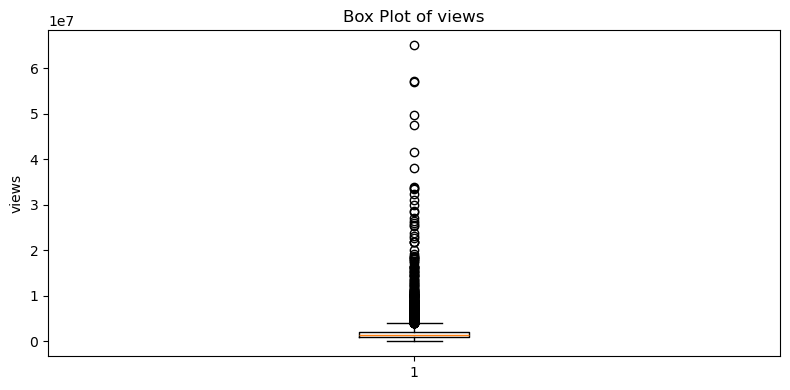

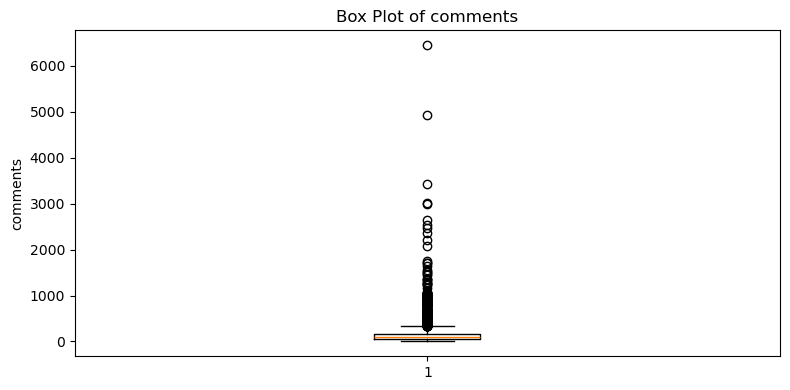

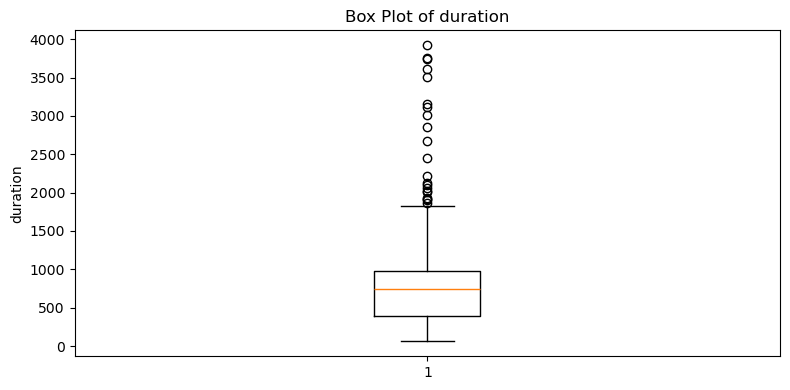

In [35]:
for col in [c for c in ["views", "comments", "duration"] if c in df.columns]:
    plt.figure(figsize=(8, 4))
    plt.boxplot(df[col].dropna())
    plt.title(f"Box Plot of {col}")
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()

## 14. Review the remaining missing values

**What this cell does:** checks the missing-value count after cleaning. The one missing `recorded_date` is intentionally retained until its correct value can be verified.

In [37]:
final_missing = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing Percentage": (df.isna().mean() * 100).round(2)
})

display(final_missing[final_missing["Missing Count"] > 0])

,Missing Count,Missing Percentage
recorded_date,1,0.02


## 15. Final data-quality report

**What this cell does:** prints the final dataset dimensions, data types, missing values, duplicate counts, and numerical summary. Use this output to document the result of your cleaning workflow.

In [38]:
print("Final dataset shape:", df.shape)

print("\nData types:")
display(df.dtypes.to_frame("Data Type"))

print("\nMissing values:")
display(df.isna().sum().to_frame("Missing Count"))

print("\nDuplicate rows:", df.duplicated().sum())

if "talk_id" in df.columns:
    print("Duplicate talk IDs:", df["talk_id"].duplicated().sum())

print("\nNumerical summary:")
display(df.select_dtypes(include="number").describe())

Final dataset shape: (4005, 19)

Data types:


,Data Type
talk_id,int64
title,object
speaker_1,object
all_speakers,object
occupations,object
about_speakers,object
views,int64
recorded_date,datetime64[ns]
published_date,datetime64[ns]
event,object



Missing values:


,Missing Count
talk_id,0
title,0
speaker_1,0
all_speakers,0
occupations,0
about_speakers,0
views,0
recorded_date,1
published_date,0
event,0



Duplicate rows: 0
Duplicate talk IDs: 0

Numerical summary:


,talk_id,views,comments,duration
count,4005.000000,4.005000e+03,4005.000000,4005.000000
mean,12432.538327,2.148006e+06,150.058677,724.011236
std,17447.576262,3.451226e+06,247.346686,361.775462
min,1.000000,0.000000e+00,0.000000,60.000000
25%,1252.000000,8.820690e+05,46.000000,393.000000
50%,2333.000000,1.375508e+06,89.000000,738.000000
75%,23777.000000,2.133110e+06,162.000000,974.000000
max,62794.000000,6.505195e+07,6449.000000,3922.000000


## 16. Save the cleaned dataset

**What this cell does:** saves the current DataFrame to a new CSV file, leaving the original CSV untouched. The file is saved in the current working directory unless an absolute path is supplied.

In [39]:
output_path = "ted_talks_cleaned.csv"

df.to_csv(output_path, index=False)

print("Cleaned dataset saved to:", os.path.abspath(output_path))
print("File exists:", os.path.exists(output_path))

Cleaned dataset saved to: C:\Users\ADITI CHAUDHARY\TED_Talk_Recommendation_System1\ted_talks_cleaned.csv
File exists: True


## 17. Conclusion

### Cleaning actions performed
- Loaded and inspected the dataset.
- Reviewed missing values and duplicate rows/IDs.
- Replaced missing or blank `all_speakers`, `occupations`, and `about_speakers` values with `"Unknown"`.
- Converted date columns to datetime and retained the unverified missing recording date.
- Imputed missing comments with the median and converted comments to integers after checking they were whole numbers.
- Trimmed leading/trailing whitespace and standardized `native_lang` codes to lowercase.
- Inspected titles, speaker fields, occupations, biographies, event names, language/topic representations, and URL structure.
- Checked numerical values, zero counts, and IQR-based potential outliers.
- Retained plausible outliers rather than deleting them automatically.
- Saved the result as `ted_talks_cleaned.csv`.

### Limitations and notes
- `"Unknown"` is a missing-information label, not original source information.
- Median-imputed comment values should be documented in downstream analysis.
- One `recorded_date` remains missing because its correct value has not been verified.
- Six zero-view records should be checked against the original source if possible.
- IQR-flagged values were not automatically removed; high values may be legitimate.
- Basic URL validation checks structure, not whether a URL is reachable.
- Review diagnostic outputs before treating every formatting or data-quality issue as resolved.

**Next step:** perform Exploratory Data Analysis (EDA) on the cleaned dataset.

In [42]:
file_path ='ted_talks_cleaned.csv' # Change this to your original CSV path if needed

df = pd.read_csv(file_path)

In [43]:
missing_summary = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing Percentage": (df.isna().mean() * 100).round(2)
})

display(missing_summary.sort_values("Missing Count", ascending=False))

,Missing Count,Missing Percentage
recorded_date,1,0.02
title,0,0.00
talk_id,0,0.00
speaker_1,0,0.00
all_speakers,0,0.00
about_speakers,0,0.00
occupations,0,0.00
views,0,0.00
published_date,0,0.00
event,0,0.00
